# Digbodha 1: Text-Prompted Motion and Collision-Risk Estimation from a Single Camera

**K Praveen Sagar (CS26M1002), Arnav Abhijit Rajurkar (CS26M1007), Madhur Vijay Patil (CS26M1024)** · M.Tech CSE (Data Science & AI), IIITDM Kancheepuram · Computer Vision course project
Code: https://github.com/spi727/digbodha · Base paper: *SAM 3: Segment Anything with Concepts* (Carion et al., arXiv:2511.16719, 2025)

Given a video and object names ("vehicle, person"), the pipeline outputs, per object and per frame: its motion with the camera's own motion removed, its **time to contact (TTC)**, whether it is on a **collision course**, and a risk label (safe / caution / danger / uncertain). No depth sensor or calibration is used.

| Stage | Type | File |
|---|---|---|
| 1. Segment + track named objects (SAM 3.1, chunked for 8 GB GPU) | deep learning | `src/segment.py` |
| 2. Camera-motion removal (Shi–Tomasi + Lucas–Kanade + RANSAC homography) | classical CV | `src/egomotion.py` |
| 3. TTC from looming (1/size line fit, Lee's tau) + collision course + risk | classical CV | `src/ttc.py` |
| Evaluation against KITTI 3D labels | | `eval/` |

**Run this notebook from the repo root** (`~/projects/digbodha`) in the `cvproj` environment.

## 1. Setup

In [1]:
import os, sys, csv, glob, json, subprocess
import numpy as np
import cv2
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("."))          # repo root
from src.ttc import TTCEstimator

KITTI  = os.path.expanduser("~/datasets/kitti_tracking")   # KITTI Tracking (training split)
SEQ, N = "0007", 300                                         # sequence and number of frames
FRAMES = f"data/kitti_{SEQ}_{N}"                             # JPG frames (made by scripts/run_kitti_eval.sh)
LABELS = f"{KITTI}/training/label_02/{SEQ}.txt"
OUT    = f"outputs/nb_kitti_{SEQ}"
FPS    = 10

# True  -> run the full pipeline with SAM 3.1 on the GPU (about 5-10 min for 300 frames on an RTX 5060)
# False -> reuse the saved SAM 3.1 + ego-motion results and re-run only the TTC/risk stage (seconds)
RUN_PIPELINE = False

def run(cmd):
    """Run a repo script and show its output."""
    p = subprocess.run([sys.executable] + cmd, capture_output=True, text=True)
    print(p.stdout)
    if p.returncode:
        print(p.stderr[-3000:])
        raise RuntimeError("command failed: " + " ".join(cmd))

def num(v):
    try:
        return float(v)
    except (TypeError, ValueError):
        return None

try:
    import torch
    print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
          "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
except ImportError:
    print("torch not installed (only needed when RUN_PIPELINE = True)")
print("frames:", FRAMES, "->", len(glob.glob(FRAMES + "/*.jpg")), "jpg")

torch 2.10.0+cu128 | CUDA: True | NVIDIA GeForce RTX 5060 Laptop GPU
frames: data/kitti_0007_300 -> 300 jpg


## 2. The principle: time to contact from looming

For an object of real height $H$ at depth $Z$, its image height is $s = fH/Z$. If it closes at constant speed $v$, then
$$\frac{1}{s} = \frac{Z}{fH} = \frac{Z_0 - v t}{fH},$$
which is a **straight line in time that reaches zero at the moment of contact**. Fitting a line to $1/s$ over the last 0.8 s and taking its zero crossing gives TTC with no lag and without knowing $f$, $H$ or $Z$ (Lee, 1976).

The lateral offset in object heights, $q = x/s$, is extrapolated to contact: miss $m = q + \dot q \cdot \mathrm{TTC}$. $|m| < 1$ means on a collision course.

Below, two synthetic objects approach a camera at 10 m/s: one head-on, one passing 4 m to the side.

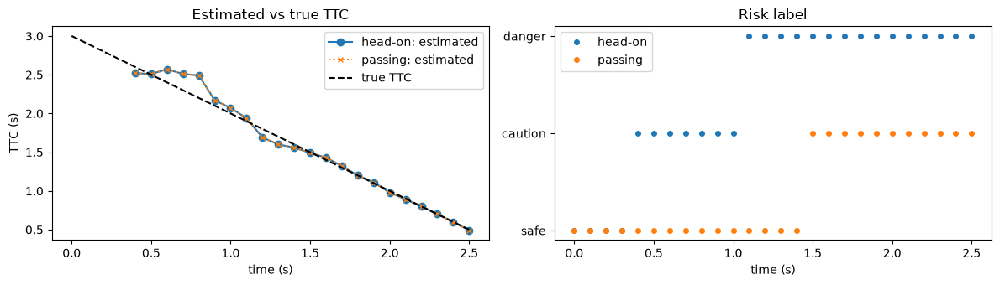

head-on  t=2.5s  true TTC 0.50s  estimated 0.49s  miss +0.20 heights  -> danger
passing  t=2.5s  true TTC 0.50s  estimated 0.49s  miss +2.65 heights  -> caution


In [2]:
f, H, v, Z0 = 700.0, 1.5, 10.0, 30.0       # focal (px), object height (m), closing speed (m/s), start depth (m)
W_IMG, H_IMG = 1242, 375
objs = {1: ("head-on", 0.3), 2: ("passing", 4.0)}   # lateral offset X (m)
est = TTCEstimator(fps=FPS)
log = {k: [] for k in objs}
for i in range(26):                          # 2.5 s
    t = i / FPS
    Z = Z0 - v * t
    items = []
    for oid, (name, X) in objs.items():
        s, xc = f * H / Z, W_IMG / 2 + f * X / Z
        items.append({"id": oid, "label": "vehicle", "raw_flow": None, "own_flow": None,
                      "box": (int(xc - 0.4 * s), int(200 - s / 2), int(xc + 0.4 * s), int(200 + s / 2))})
    res = est.update_boxes(i, items, W_IMG, H_IMG)
    for oid in objs:
        log[oid].append((t, Z / v, res[oid]["ttc_s"], res[oid]["risk"], res[oid]["miss_widths"]))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for oid, (name, X) in objs.items():
    t, true, ttc, risk, miss = zip(*log[oid])
    ax[0].plot(t, [x if x is not None and x < 20 else np.nan for x in ttc], "o-" if oid == 1 else "x:", ms=6 if oid == 1 else 5, label=f"{name}: estimated")
ax[0].plot(t, true, "k--", label="true TTC")
ax[0].set(xlabel="time (s)", ylabel="TTC (s)", title="Estimated vs true TTC"); ax[0].legend()
for oid, (name, X) in objs.items():
    ax[1].plot([r[0] for r in log[oid]], [r[3] for r in log[oid]], "o", ms=4, label=name)
ax[1].set(xlabel="time (s)", title="Risk label"); ax[1].legend()
plt.tight_layout(); plt.show()
for oid, (name, X) in objs.items():
    t, true, ttc, risk, miss = log[oid][-1]
    print(f"{name:8s} t={t:.1f}s  true TTC {true:.2f}s  estimated {ttc:.2f}s  miss {miss:+.2f} heights  -> {risk}")

## 3. Run the pipeline on a KITTI sequence

`analyze.py` runs all three stages and writes `frames.csv` (one row per object per frame), `tracks.json` (one summary per object) and `annotated.mp4`.

In [3]:
os.makedirs(OUT, exist_ok=True)
if RUN_PIPELINE:
    run(["analyze.py", "--video", FRAMES, "--fps", str(FPS), "--prompts", "vehicle,person", "--out", OUT])
else:
    # saved SAM 3.1 + ego-motion output of the same sequence; only the TTC/risk stage is re-run
    run(["eval/rescore.py", "--pred", f"outputs/kitti_{SEQ}/frames.csv", "--frames", FRAMES,
         "--fps", str(FPS), "--out", f"{OUT}/frames.csv"])
PRED = f"{OUT}/frames.csv"
rows = list(csv.DictReader(open(PRED)))
print(len(rows), "object-frames,", len({r['id'] for r in rows}), "tracked objects")
from collections import Counter
print("risk labels:", dict(Counter(r["risk"] for r in rows)))

re-scored 1640 object-frames (289 frames, image 1242x375) -> outputs/nb_kitti_0007/frames.csv

1640 object-frames, 36 tracked objects
risk labels: {'safe': 1248, 'caution': 234, 'danger': 22, 'uncertain': 136}


## 4. What the output looks like

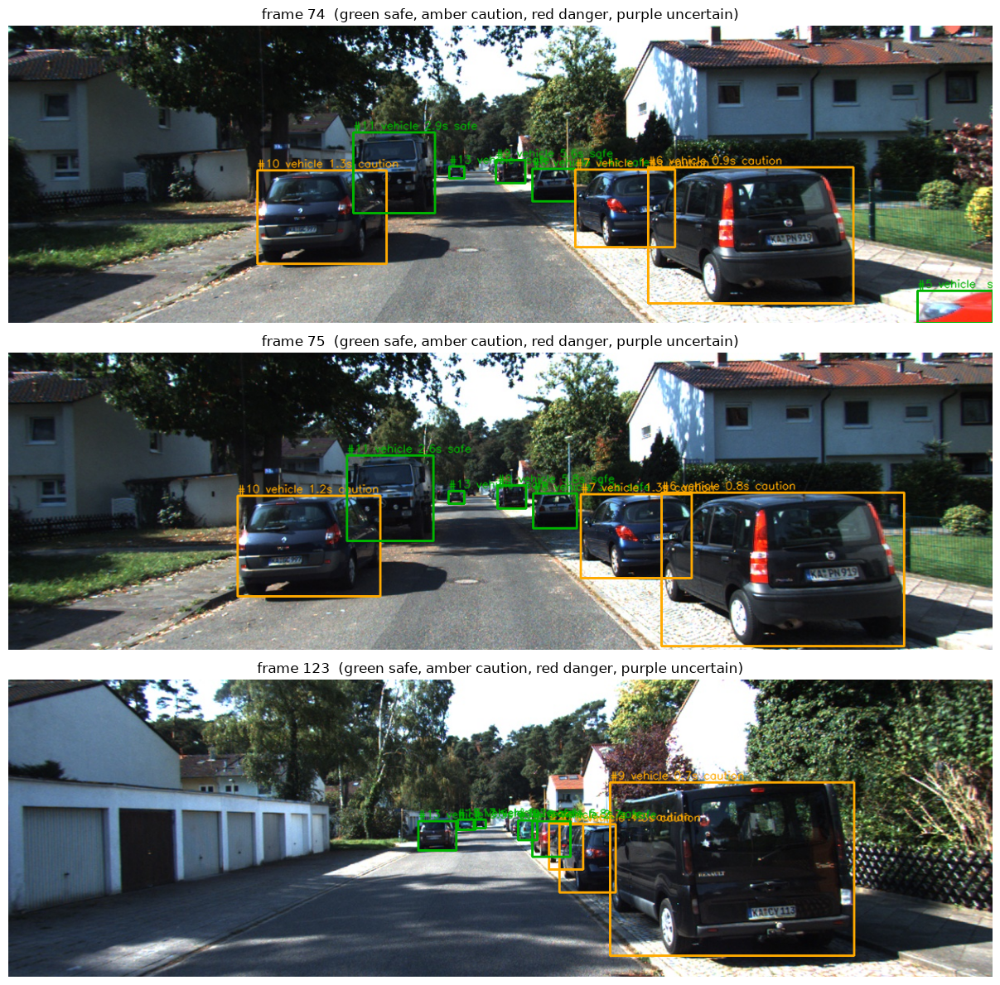

In [4]:
COLORS = {"safe": (0, 180, 0), "uncertain": (180, 0, 180), "caution": (0, 170, 255), "danger": (0, 0, 255)}
by_frame = {}
for r in rows:
    by_frame.setdefault(int(r["frame"]), []).append(r)
frames = sorted(glob.glob(FRAMES + "/*.jpg"))

def draw(fr):
    img = cv2.imread(frames[fr])
    for r in by_frame.get(fr, []):
        c = COLORS.get(r["risk"], (200, 200, 200))
        x0, y0, x1, y1 = (int(float(r[k])) for k in ("bx0", "by0", "bx1", "by1"))
        cv2.rectangle(img, (x0, y0), (x1, y1), c, 2)
        ttc = num(r["ttc_s"])
        txt = f"#{r['id']} {r['label']} " + (f"{ttc:.1f}s" if ttc is not None and ttc < 10 else "") + f" {r['risk']}"
        cv2.putText(img, txt, (x0, max(12, y0 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
    return img[:, :, ::-1]

# show the frames with the most caution/danger objects
score = {fr: sum(r["risk"] in ("caution", "danger") for r in rs) for fr, rs in by_frame.items()}
show = sorted(sorted(score, key=score.get, reverse=True)[:3])
fig, axes = plt.subplots(len(show), 1, figsize=(14, 4 * len(show)))
for ax, fr in zip(np.atleast_1d(axes), show):
    ax.imshow(draw(fr)); ax.set_title(f"frame {fr}  (green safe, amber caution, red danger, purple uncertain)"); ax.axis("off")
plt.tight_layout(); plt.show()

### The whole sequence as a video, at 0.25× speed

Every frame is drawn from `frames.csv` as above (box colour = risk, label = ID, class, TTC) and written as an H.264 MP4 that plays inside the notebook. KITTI is 10 FPS, so 0.25× plays at 2.5 FPS.

In [5]:
SPEED = 0.25                                   # playback speed (1.0 = real time)
VID_W, VID_H = 960, 288                        # video size (multiples of 8; keeps the notebook small)
QUALITY = 5                                    # 0-10, higher = bigger file
VIDEO = f"{OUT}/annotated_{SPEED:g}x.mp4"
try:
    import imageio_ffmpeg                      # bundles its own ffmpeg binary (no system ffmpeg needed)
except ImportError:
    run(["-m", "pip", "install", "-q", "imageio", "imageio-ffmpeg"])
    import imageio_ffmpeg
import imageio.v2 as imageio
from IPython.display import Video, display

writer = imageio.get_writer(VIDEO, format="FFMPEG", fps=FPS * SPEED, codec="libx264", quality=QUALITY,
                            macro_block_size=8, ffmpeg_log_level="error")
for fr in range(len(frames)):
    img = np.ascontiguousarray(cv2.resize(draw(fr), (VID_W, VID_H), interpolation=cv2.INTER_AREA))
    cv2.putText(img, f"frame {fr}  t={fr / FPS:.1f}s  ({SPEED:g}x)", (10, 22),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
    writer.append_data(img)
writer.close()
print(f"{VIDEO}: {len(frames)} frames, {len(frames) / (FPS * SPEED):.0f} s, {os.path.getsize(VIDEO) / 1e6:.1f} MB")
display(Video(VIDEO, embed=True, width=960))

outputs/nb_kitti_0007/annotated_0.25x.mp4: 300 frames, 120 s, 10.1 MB


## 5. Evaluation against KITTI ground truth

KITTI has no TTC labels, so they are derived from its 3D boxes: true TTC = $Z / (-\dot Z)$ (line fit over ±4 frames), true miss = lateral position at contact / object height. Predictions are matched to labels by box IoU ≥ 0.5.


=== KITTI evaluation: 289 frames, 1090 GT objects within 40 m, 90.5% matched ===

Time to contact (objects approaching in truth and in our estimate):
  ttc_all          {'n': 849, 'median_abs_s': 0.25, 'mean_abs_s': 0.61, 'median_rel_pct': 14.6, 'within_20pct': 67.4}
  ttc_reliable     {'n': 681, 'median_abs_s': 0.22, 'mean_abs_s': 0.42, 'median_rel_pct': 12.3, 'within_20pct': 78.9}
  ttc_unreliable   {'n': 168, 'median_abs_s': 0.55, 'mean_abs_s': 1.41, 'median_rel_pct': 69.5, 'within_20pct': 20.8}
  reliable, by true depth:
    0-10 m   {'n': 103, 'median_abs_s': 0.19, 'mean_abs_s': 0.31, 'median_rel_pct': 17.4, 'within_20pct': 68.9}
    10-20 m  {'n': 286, 'median_abs_s': 0.19, 'mean_abs_s': 0.3, 'median_rel_pct': 12.0, 'within_20pct': 83.9}
    20-40 m  {'n': 292, 'median_abs_s': 0.32, 'mean_abs_s': 0.57, 'median_rel_pct': 10.2, 'within_20pct': 77.4}

Approach detection: {'tp': 849, 'fp': 5, 'fn': 74, 'precision': 0.994, 'recall': 0.92}

Risk (rows = truth, columns = ours):
       

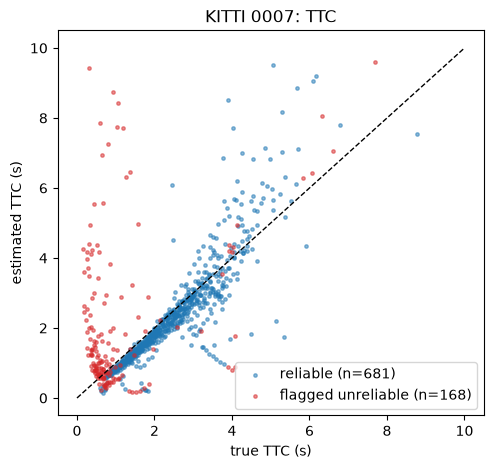

In [6]:
EVAL = f"{OUT}/eval"
run(["eval/evaluate_kitti.py", "--pred", PRED, "--labels", LABELS, "--fps", str(FPS), "--out", EVAL])

m = list(csv.DictReader(open(f"{EVAL}/matched.csv")))
pts = [(num(r["gt_ttc"]), num(r["pred_ttc"]), r["reliable"] in ("True", "true", "1"))
       for r in m if num(r["gt_ttc"]) is not None and num(r["pred_ttc"]) is not None]
pts = [p for p in pts if p[0] < 10 and p[1] < 10]
plt.figure(figsize=(5.5, 5))
for rel, c, lab in ((True, "tab:blue", "reliable"), (False, "tab:red", "flagged unreliable")):
    g = [(a, b) for a, b, r in pts if r == rel]
    if g:
        plt.scatter(*zip(*g), s=6, alpha=0.5, c=c, label=f"{lab} (n={len(g)})")
plt.plot([0, 10], [0, 10], "k--", lw=1)
plt.xlabel("true TTC (s)"); plt.ylabel("estimated TTC (s)"); plt.title(f"KITTI {SEQ}: TTC"); plt.legend()
plt.show()

## 6. All sequences: tuning set and held-out set

Pools the saved evaluations (made with `scripts/run_kitti_eval.sh` and `scripts/rescore_all.sh`): tuning sequences 0013, 0001, 0020 and held-out sequences 0019, 0007. Prints TTC accuracy, alert precision/recall, error attribution and event-level warnings.

In [7]:
for name, tag, seqs in (("TUNING", "v5_nodebounce", ["0013", "0001", "0020"]),
                        ("HELD-OUT", "heldout_nodebounce", ["0019", "0007"])):
    dirs = [f"outputs/eval_{s}_{tag}" for s in seqs if os.path.exists(f"outputs/eval_{s}_{tag}/matched.csv")]
    if not dirs:
        print(f"{name}: no saved evaluations found ({tag}); run scripts/rescore_all.sh first"); continue
    print("#" * 30, name, "#" * 30)
    run(["eval/aggregate.py", *dirs, "--out", f"outputs/eval_pooled_{tag}"])
    run(["eval/analyze_errors.py", *dirs])

############################## TUNING ##############################



=== Pooled over eval_0013_v5_nodebounce, eval_0001_v5_nodebounce, eval_0020_v5_nodebounce: 4739 matched object-frames ===
TTC all       : {'n': 3428, 'median_abs_s': 0.3, 'median_rel_pct': 14.7, 'within_20pct': 63.3}
TTC reliable  : {'n': 2791, 'median_abs_s': 0.27, 'median_rel_pct': 12.9, 'within_20pct': 70.9}
   0-10 m    {'n': 352, 'median_abs_s': 0.14, 'median_rel_pct': 12.3, 'within_20pct': 74.1}
   10-20 m   {'n': 1375, 'median_abs_s': 0.24, 'median_rel_pct': 12.0, 'within_20pct': 76.1}
   20-40 m   {'n': 1064, 'median_abs_s': 0.49, 'median_rel_pct': 14.5, 'within_20pct': 63.3}
Approach      : {'tp': 3428, 'fp': 125, 'fn': 425, 'precision': 0.965, 'recall': 0.89}
Risk (rows = truth, cols = ours):
                  safe uncertain   caution    danger
  safe            3196       122       302        23
  caution          201       256       601        24
  danger             8         1         3         2
Alerts        : {'tp': 630, 'fp': 325, 'fn': 466, 'fn_flagged_uncertain': 2


=== Pooled over eval_0019_heldout_nodebounce, eval_0007_heldout_nodebounce: 2408 matched object-frames ===
TTC all       : {'n': 1735, 'median_abs_s': 0.33, 'median_rel_pct': 13.6, 'within_20pct': 66.3}
TTC reliable  : {'n': 1427, 'median_abs_s': 0.28, 'median_rel_pct': 11.5, 'within_20pct': 75.8}
   0-10 m    {'n': 371, 'median_abs_s': 0.23, 'median_rel_pct': 11.9, 'within_20pct': 73.6}
   10-20 m   {'n': 653, 'median_abs_s': 0.26, 'median_rel_pct': 11.2, 'within_20pct': 77.3}
   20-40 m   {'n': 403, 'median_abs_s': 0.43, 'median_rel_pct': 11.7, 'within_20pct': 75.4}
Approach      : {'tp': 1735, 'fp': 125, 'fn': 194, 'precision': 0.933, 'recall': 0.899}
Risk (rows = truth, cols = ours):
                  safe uncertain   caution    danger
  safe            1672        76       130        44
  caution          137       118       199        12
  danger             7         7         5         1
Alerts        : {'tp': 217, 'fp': 174, 'fn': 269, 'fn_flagged_uncertain': 125, 'fn_called_

## 7. Summary

| | Tuning (0013+0001+0020) | Held-out (0019+0007) |
|---|---|---|
| Median TTC error, reliable estimates | 12.9% (0.27 s) | 11.5% (0.28 s) |
| Median TTC error, flagged unreliable | 43% | 60–70% |
| Approach detection precision / recall | 0.97 / 0.89 | 0.93 / 0.90 |
| Hazard events warned | 87% of 149 | 70% of 57 |

- **Works:** TTC from looming is accurate at all depths up to 40 m, and the reliability flag separates good estimates from bad ones on unseen data.
- **Weak:** the final risk label. Most false warnings are TTC values just across a threshold, most misses are objects cut by the frame edge, and crowds exceed SAM 3.1's 16 object slots.
- **Next (thesis):** metric depth / 3D spatial awareness, and using these per-frame outputs to label video for a vision-language model.